In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/AQI.csv")


print(df.head())

  StationId             Datetime  PM2.5    PM10    NO    NO2    NOx    NH3  \
0     AP001  2017-11-24 17:00:00  60.50   98.00  2.35  30.80  18.25   8.50   
1     AP001  2017-11-24 18:00:00  65.50  111.25  2.70  24.20  15.07   9.77   
2     AP001  2017-11-24 19:00:00  80.00  132.00  2.10  25.18  15.15  12.02   
3     AP001  2017-11-24 20:00:00  81.50  133.25  1.95  16.25  10.23  11.58   
4     AP001  2017-11-24 21:00:00  75.25  116.00  1.43  17.48  10.43  12.03   

    CO    SO2      O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  0.1  11.85  126.40      0.1     6.10    0.10  NaN        NaN  
1  0.1  13.17  117.12      0.1     6.25    0.15  NaN        NaN  
2  0.1  12.08   98.98      0.2     5.98    0.18  NaN        NaN  
3  0.1  10.47  112.20      0.2     6.72    0.10  NaN        NaN  
4  0.1   9.12  106.35      0.2     5.75    0.08  NaN        NaN  


C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25328\3339799981.py:3: DtypeWarning: Columns (0: AQI_Bucket) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/AQI.csv")


In [5]:
print(df["StationId"].nunique())

110


In [6]:
print(sorted(df["StationId"].unique()))

['AP001', 'AP005', 'AS001', 'BR005', 'BR006', 'BR007', 'BR008', 'BR009', 'BR010', 'CH001', 'DL001', 'DL002', 'DL003', 'DL004', 'DL005', 'DL006', 'DL007', 'DL008', 'DL009', 'DL010', 'DL011', 'DL012', 'DL013', 'DL014', 'DL015', 'DL016', 'DL017', 'DL018', 'DL019', 'DL020', 'DL021', 'DL022', 'DL023', 'DL024', 'DL025', 'DL026', 'DL027', 'DL028', 'DL029', 'DL030', 'DL031', 'DL032', 'DL033', 'DL034', 'DL035', 'DL036', 'DL037', 'DL038', 'GJ001', 'HR011', 'HR012', 'HR013', 'HR014', 'JH001', 'KA002', 'KA003', 'KA004', 'KA005', 'KA006', 'KA007', 'KA008', 'KA009', 'KA010', 'KA011', 'KL002', 'KL004', 'KL007', 'KL008', 'MH005', 'MH006', 'MH007', 'MH008', 'MH009', 'MH010', 'MH011', 'MH012', 'MH013', 'MH014', 'ML001', 'MP001', 'MZ001', 'OD001', 'OD002', 'PB001', 'RJ004', 'RJ005', 'RJ006', 'TG001', 'TG002', 'TG003', 'TG004', 'TG005', 'TG006', 'TN001', 'TN002', 'TN003', 'TN004', 'TN005', 'UP012', 'UP013', 'UP014', 'UP015', 'UP016', 'WB007', 'WB008', 'WB009', 'WB010', 'WB011', 'WB012', 'WB013']


In [7]:
station_counts = (
    df.groupby("StationId")["AQI"]
      .count()
      .sort_values(ascending=False)
)

print(station_counts)

StationId
DL031    39207
UP012    39176
UP014    38890
TN001    38698
KA009    36580
         ...  
HR013     2705
MZ001     2528
BR006     2437
BR005     1689
DL011        0
Name: AQI, Length: 110, dtype: int64


In [8]:
delhi_df = df[df["StationId"].str.startswith("DL")].copy()

print(delhi_df.shape)

(1087388, 16)


In [9]:
print(delhi_df["AQI"].isnull().sum())
print(delhi_df["AQI"].notnull().sum())

241288
846100


In [10]:
delhi_df = delhi_df.dropna(subset=["AQI"])

print(delhi_df.shape)

(846100, 16)


In [12]:
delhi_df["Datetime"] = pd.to_datetime(delhi_df["Datetime"])
delhi_df = delhi_df.sort_values("Datetime")

In [13]:
delhi_df.to_csv("../data/processed/delhi_bootstrap.csv", index=False)

Bootstrap Dataset

In [15]:
import pandas as pd

df = pd.read_csv("../data/raw/AQI.csv")

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25328\888681790.py:3: DtypeWarning: Columns (0: AQI_Bucket) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/AQI.csv")


In [16]:
delhi_df = df[df["StationId"].str.startswith("DL")].copy()

print(delhi_df.shape)

(1087388, 16)


In [17]:
delhi_df = delhi_df.dropna(subset=["AQI"])

print(delhi_df.shape)

(846100, 16)


In [18]:
delhi_df["Datetime"] = pd.to_datetime(delhi_df["Datetime"])

In [19]:
delhi_df = delhi_df.sort_values("Datetime")

In [20]:
bootstrap_df = (
    delhi_df
    .groupby("Datetime")
    .agg({
        "AQI": "median",
        "PM2.5": "median",
        "PM10": "median",
        "NO2": "median",
        "NO": "median",
        "NOx": "median",
        "NH3": "median",
        "CO": "median",
        "SO2": "median",
        "O3": "median"
    })
    .reset_index()
)

In [21]:
bootstrap_df.head()

,Datetime,AQI,PM2.5,PM10,NO2,NO,NOx,NH3,CO,SO2,O3
0,2015-01-01 16:00:00,456.5,211.510,340.66,30.210,14.805,43.905,38.34,10.975,14.0,110.16
1,2015-01-01 17:00:00,450.0,191.120,257.40,31.250,15.510,44.820,40.96,12.225,18.5,109.76
2,2015-01-01 18:00:00,446.5,218.440,351.01,30.825,18.270,47.145,40.84,13.445,24.5,123.91
3,2015-01-01 19:00:00,475.0,296.805,600.95,30.640,26.560,54.505,38.74,14.340,32.0,159.48
4,2015-01-01 20:00:00,480.0,336.430,714.63,29.655,31.295,57.805,41.50,8.845,22.5,173.27


In [22]:
bootstrap_df.isnull().sum()

Datetime       0
AQI            0
PM2.5        144
PM10        3119
NO2          126
NO           168
NOx          223
NH3         2152
CO          2739
SO2         2895
O3          1960
dtype: int64

In [23]:
bootstrap_df.to_csv(
    "../data/processed/delhi_bootstrap.csv",
    index=False
)

In [24]:
print(bootstrap_df["Datetime"].min())
print(bootstrap_df["Datetime"].max())

2015-01-01 16:00:00
2020-07-01 00:00:00


In [28]:
import pandas as pd

weather = pd.read_csv("../data/weather/delhi_weather.csv")

print(weather.head())

print(weather.shape)

print(weather.columns)

print(weather.isnull().sum())

              Datetime  tempC  humidity  precipMm  windSpeedKmh  windDirDeg
0  2015-01-01 00:00:00   12.5        81       0.0           7.6         360
1  2015-01-01 01:00:00   12.1        83       0.0           7.9         357
2  2015-01-01 02:00:00   11.8        84       0.0           7.9           3
3  2015-01-01 03:00:00   13.0        80       0.0           6.9           9
4  2015-01-01 04:00:00   15.6        69       0.0           3.9          22
(48216, 6)
Index(['Datetime', 'tempC', 'humidity', 'precipMm', 'windSpeedKmh',
       'windDirDeg'],
      dtype='str')
Datetime        0
tempC           0
humidity        0
precipMm        0
windSpeedKmh    0
windDirDeg      0
dtype: int64


In [29]:
bootstrap_df["Datetime"] = pd.to_datetime(bootstrap_df["Datetime"])
weather["Datetime"] = pd.to_datetime(weather["Datetime"])

In [30]:
merged_df = bootstrap_df.merge(
    weather,
    on="Datetime",
    how="inner"
)

print(merged_df.shape)
merged_df.head()

(47694, 16)


,Datetime,AQI,PM2.5,PM10,NO2,NO,NOx,NH3,CO,SO2,O3,tempC,humidity,precipMm,windSpeedKmh,windDirDeg
0,2015-01-01 16:00:00,456.5,211.510,340.66,30.210,14.805,43.905,38.34,10.975,14.0,110.16,15.8,73,0.0,6.3,167
1,2015-01-01 17:00:00,450.0,191.120,257.40,31.250,15.510,44.820,40.96,12.225,18.5,109.76,15.5,76,0.0,6.2,159
2,2015-01-01 18:00:00,446.5,218.440,351.01,30.825,18.270,47.145,40.84,13.445,24.5,123.91,14.8,80,0.0,5.3,152
3,2015-01-01 19:00:00,475.0,296.805,600.95,30.640,26.560,54.505,38.74,14.340,32.0,159.48,15.1,80,0.0,3.0,104
4,2015-01-01 20:00:00,480.0,336.430,714.63,29.655,31.295,57.805,41.50,8.845,22.5,173.27,14.7,83,0.0,2.3,72


In [31]:
merged_df.isnull().sum()

Datetime           0
AQI                0
PM2.5            144
PM10            3119
NO2              126
NO               168
NOx              223
NH3             2152
CO              2739
SO2             2895
O3              1960
tempC              0
humidity           0
precipMm           0
windSpeedKmh       0
windDirDeg         0
dtype: int64

In [32]:
merged_df.to_csv(
    "../data/processed/delhi_bootstrap_weather.csv",
    index=False
)

In [33]:
print(delhi_df["StationId"].value_counts())

StationId
DL031    39207
DL002    35979
DL021    35903
DL028    33885
DL019    31688
DL013    28795
DL007    27851
DL034    27323
DL033    24763
DL012    22864
DL004    22740
DL017    22074
DL030    21844
DL008    21335
DL025    21295
DL010    20942
DL024    20939
DL003    20902
DL018    20891
DL015    20832
DL014    20802
DL027    20765
DL026    20710
DL016    20685
DL032    20681
DL009    20674
DL038    20662
DL035    20542
DL037    20486
DL023    20238
DL022    20130
DL005    17195
DL036    17184
DL020    16910
DL006    16299
DL029    16263
DL001    13822
Name: count, dtype: int64


In [34]:
coverage = (
    df[df["StationId"].str.startswith("DL")]
      .groupby("StationId")
      .agg(
          total_rows=("AQI", "size"),
          valid_aqi=("AQI", lambda x: x.notna().sum())
      )
)

coverage["completeness"] = (
    coverage["valid_aqi"] / coverage["total_rows"]
)

coverage = coverage.sort_values(
    ["completeness", "valid_aqi"],
    ascending=False
)

print(coverage.head(10))

KeyError: 'StationId'

In [35]:
print(df.columns)

Index(['Datetime', 'tempC', 'humidity', 'precipMm', 'windSpeedKmh',
       'windDirDeg'],
      dtype='str')


In [36]:
import pandas as pd

raw_df = pd.read_csv("../data/raw/AQI.csv")

coverage = (
    raw_df[raw_df["StationId"].str.startswith("DL")]
    .groupby("StationId")
    .agg(
        total_rows=("AQI", "size"),
        valid_aqi=("AQI", lambda x: x.notna().sum())
    )
)

coverage["completeness"] = (
    coverage["valid_aqi"] / coverage["total_rows"]
)

coverage = coverage.sort_values(
    ["completeness", "valid_aqi"],
    ascending=False
)

print(coverage.head(10))

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25328\69504891.py:3: DtypeWarning: Columns (0: AQI_Bucket) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv("../data/raw/AQI.csv")


           total_rows  valid_aqi  completeness
StationId                                     
DL010           21137      20942      0.990774
DL024           21134      20939      0.990773
DL003           21136      20902      0.988929
DL018           21144      20891      0.988034
DL015           21136      20832      0.985617
DL005           17454      17195      0.985161
DL036           17478      17184      0.983179
DL027           21134      20765      0.982540
DL026           21134      20710      0.979938
DL016           21136      20685      0.978662


In [40]:
import requests

# The v3 endpoint for Delhi locations
url = "https://api.openaq.org/v3/locations"
params = {
    "cities_id": 286, # OpenAQ's internal ID for Delhi
    "limit": 200
}

# Add your new API key here
headers = {
    "X-API-Key": "8b9ca36f6f781c95db339cb2cf5dfd03681e41e18a7a44d3a049e33687daa50c"
}

response = requests.get(url, params=params, headers=headers)
data = response.json()

target_stations = ["Mandir Marg", "R.K. Puram", "ITO"]

print("--- OpenAQ Location ID Mapping ---")

for result in data.get('results', []):
    for target in target_stations:
        if target.lower() in result['name'].lower():
            print(f"Target: {target:<15} | OpenAQ ID: {result['id']}")

--- OpenAQ Location ID Mapping ---
Target: Mandir Marg     | OpenAQ ID: 236


In [42]:
import requests
import pandas as pd
from datetime import datetime, timedelta

# The 4 OpenAQ Location IDs you gathered (Replace with your actual IDs)
location_ids = [235,236] 

headers = {"X-API-Key": "8b9ca36f6f781c95db339cb2cf5dfd03681e41e18a7a44d3a049e33687daa50c"}

# Define the 3-year historical window
end_date = datetime.utcnow()
start_date = end_date - timedelta(days=3*365)

# Format dates for the API
date_to = end_date.strftime('%Y-%m-%dT%H:%M:%SZ')
date_from = start_date.strftime('%Y-%m-%dT%H:%M:%SZ')

all_data = []

for loc_id in location_ids:
    print(f"Fetching sensors for Location {loc_id}...")
    loc_response = requests.get(f"https://api.openaq.org/v3/locations/{loc_id}", headers=headers).json()
    
    # Extract the array of sensors (PM2.5, PM10, etc.) for this location
    sensors = loc_response['results'][0]['sensors']
    
    for sensor in sensors:
        sensor_id = sensor['id']
        parameter = sensor['parameter']['name']
        print(f"  -> Pulling 3 years of {parameter} (Sensor ID: {sensor_id})")
        
        page = 1
        while True:
            # Hitting the precomputed hours endpoint for data efficiency
            url = f"https://api.openaq.org/v3/sensors/{sensor_id}/hours"
            params = {
                "date_from": date_from,
                "date_to": date_to,
                "limit": 1000, # Maximize the payload per request
                "page": page
            }
            
            res = requests.get(url, headers=headers, params=params).json()
            results = res.get('results', [])
            
            if not results:
                break
                
            for row in results:
                all_data.append({
                    "location_id": loc_id,
                    "parameter": parameter,
                    "datetime": row['period']['datetimeFrom']['utc'], # <--- CORRECTED
                    "value": row['value']
                })
            
            # If we hit a page with less than 1000 results, we reached the end
            if len(results) < 1000:
                break
                
            page += 1

# Convert to a DataFrame and pivot into the "wide" format Prophet expects
df = pd.DataFrame(all_data)
df_wide = df.pivot_table(index=['location_id', 'datetime'], columns='parameter', values='value').reset_index()

# Save it locally so you never have to run this massive pull again
df_wide.to_csv("openaq_3yr_history.csv", index=False)
print("Download complete and saved to openaq_3yr_history.csv!")

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25328\470808955.py:11: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end_date = datetime.utcnow()


Fetching sensors for Location 235...
  -> Pulling 3 years of co (Sensor ID: 12235605)
  -> Pulling 3 years of co (Sensor ID: 385)
  -> Pulling 3 years of no (Sensor ID: 12235606)
  -> Pulling 3 years of no2 (Sensor ID: 12235607)
  -> Pulling 3 years of no2 (Sensor ID: 382)
  -> Pulling 3 years of nox (Sensor ID: 14340864)
  -> Pulling 3 years of o3 (Sensor ID: 12235608)
  -> Pulling 3 years of o3 (Sensor ID: 380)
  -> Pulling 3 years of pm10 (Sensor ID: 12235609)
  -> Pulling 3 years of pm10 (Sensor ID: 381)
  -> Pulling 3 years of pm25 (Sensor ID: 12235610)
  -> Pulling 3 years of pm25 (Sensor ID: 384)
  -> Pulling 3 years of relativehumidity (Sensor ID: 12235611)
  -> Pulling 3 years of so2 (Sensor ID: 12235612)
  -> Pulling 3 years of so2 (Sensor ID: 383)
  -> Pulling 3 years of temperature (Sensor ID: 12235613)
  -> Pulling 3 years of wind_direction (Sensor ID: 14340865)
  -> Pulling 3 years of wind_speed (Sensor ID: 14340866)
Fetching sensors for Location 236...
  -> Pulling 3 yea

In [43]:
import pandas as pd

# 1. Load the massive dataset you just downloaded
print("Loading the massive dataset...")
df_wide = pd.read_csv("openaq_3yr_history.csv")

# 2. Identify the exact columns we need for Phase A
# OpenAQ usually returns parameters in lowercase ('pm25', 'pm10')
target_columns = ['location_id', 'datetime', 'pm25', 'pm10']

# We use list comprehension just in case a specific station was missing pm10 entirely
columns_to_keep = [col for col in target_columns if col in df_wide.columns]

# Filter the dataframe to drop all the unnecessary gas sensors
df_filtered = df_wide[columns_to_keep]

# 3. Split into 4 independent station datasets and save them
for loc_id, group in df_filtered.groupby('location_id'):
    # Dropping the location_id column since the file name implies it
    group = group.drop(columns=['location_id'])
    
    # Save as independent CSVs (e.g., "235_base.csv")
    file_name = f"{loc_id}_base.csv"
    group.to_csv(file_name, index=False)
    print(f"Saved optimized dataset for Phase A: {file_name}")

Loading the massive dataset...
Saved optimized dataset for Phase A: 235_base.csv
Saved optimized dataset for Phase A: 236_base.csv


In [45]:
import requests
import pandas as pd
from datetime import datetime, timedelta

# Anand Vihar (235) and Mandir Marg (236)
stations = {
    235: {"lat": 28.6508, "lon": 77.3152},   
    236: {"lat": 28.6341, "lon": 77.2005}    
}

end_date = datetime.utcnow().date()
start_date = end_date - timedelta(days=3*365)

# The ultimate hourly string for AQI forecasting
hourly_params = "temperature_2m,relative_humidity_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m"

for loc_id, coords in stations.items():
    print(f"Fetching comprehensive 3-year weather data for Location {loc_id}...")
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    
    params = {
        "latitude": coords["lat"],
        "longitude": coords["lon"],
        "start_date": start_date.strftime('%Y-%m-%d'),
        "end_date": end_date.strftime('%Y-%m-%d'),
        "hourly": hourly_params,
        "timezone": "UTC"
    }
    
    response = requests.get(url, params=params)
    data = response.json()
    
    hourly_data = data["hourly"]
    
    # Map all the new arrays into the dataframe
    df_weather = pd.DataFrame({
        "datetime": hourly_data["time"],
        "temperature": hourly_data["temperature_2m"],
        "humidity": hourly_data["relative_humidity_2m"],
        "precipitation": hourly_data["precipitation"],
        "pressure": hourly_data["surface_pressure"],
        "cloud_cover": hourly_data["cloud_cover"],
        "wind_speed": hourly_data["wind_speed_10m"],
        "wind_direction": hourly_data["wind_direction_10m"]
    })
    
    # Format to match OpenAQ: '2023-01-01T00:00:00Z'
    df_weather['datetime'] = pd.to_datetime(df_weather['datetime']).dt.strftime('%Y-%m-%dT%H:%M:%SZ')
    
    file_name = f"{loc_id}_weather_comprehensive.csv"
    df_weather.to_csv(file_name, index=False)
    print(f"  -> Saved {file_name}")

print("Comprehensive weather data downloaded!")

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25328\1806032073.py:11: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end_date = datetime.utcnow().date()


Fetching comprehensive 3-year weather data for Location 235...
  -> Saved 235_weather_comprehensive.csv
Fetching comprehensive 3-year weather data for Location 236...
  -> Saved 236_weather_comprehensive.csv
Comprehensive weather data downloaded!


In [47]:
import pandas as pd

stations = [235, 236]

for loc_id in stations:
    print(f"Merging datasets for Station {loc_id}...")
    
    # 1. Load the pollution and weather datasets
    df_base = pd.read_csv(f"{loc_id}.csv")
    # If you used the comprehensive script, change this to "{loc_id}_weather_comprehensive.csv"
    df_weather = pd.read_csv(f"{loc_id}_weather_comprehensive.csv") 
    
    # 2. Merge them strictly on the datetime column
    df_merged = pd.merge(df_base, df_weather, on="datetime", how="inner")
    
    # 3. Save the combined dataset
    file_name = f"{loc_id}_merged.csv"
    df_merged.to_csv(file_name, index=False)
    print(f"  -> Successfully saved {file_name}")

Merging datasets for Station 235...
  -> Successfully saved 235_merged.csv
Merging datasets for Station 236...
  -> Successfully saved 236_merged.csv


In [48]:
import pandas as pd

df = pd.read_csv("../data/historical/processed/235_merged.csv")

print(df.shape)
print(df.head())
print(df.isna().sum())

(0, 10)
Empty DataFrame
Columns: [datetime, pm25, pm10, temperature, humidity, precipitation, pressure, cloud_cover, wind_speed, wind_direction]
Index: []
datetime          0
pm25              0
pm10              0
temperature       0
humidity          0
precipitation     0
pressure          0
cloud_cover       0
wind_speed        0
wind_direction    0
dtype: int64


In [49]:
import pandas as pd

raw = pd.read_csv("../data/historical/raw/235.csv")

print(raw.head())
print(raw["datetime"].iloc[0])
print(raw["datetime"].dtype)

               datetime   pm25   pm10
0  2016-02-05T13:30:00Z  132.0  437.0
1  2016-02-05T14:00:00Z  132.0  437.0
2  2016-02-06T05:00:00Z  255.0  357.0
3  2016-02-06T06:00:00Z  176.0  341.0
4  2016-02-08T05:00:00Z  186.0  318.0
2016-02-05T13:30:00Z
str


In [52]:
print(raw["datetime"].iloc[0])

2016-02-05T13:30:00Z


In [ ]:
weather = pd.read_csv("../data/historical/weather/235_weather_comprehensive.csv")

print(weather.head())
print(weather["datetime"].iloc[0])
print(weather["datetime"].dtype)

               datetime  temperature  humidity  precipitation  pressure  \
0  2023-07-13T00:00:00Z         26.3        93            0.7     976.8   
1  2023-07-13T01:00:00Z         26.7        90            0.0     977.2   
2  2023-07-13T02:00:00Z         27.6        88            0.0     977.8   
3  2023-07-13T03:00:00Z         28.8        83            0.0     978.4   
4  2023-07-13T04:00:00Z         29.8        79            0.0     978.7   

   cloud_cover  wind_speed  wind_direction  
0           89        10.3              65  
1           79        10.1              94  
2           70        10.5              94  
3           98        14.1              96  
4          100        12.0              97  
2023-07-13T00:00:00Z
str


In [54]:
raw = pd.read_csv("../data/historical/raw/235.csv")

print(raw["datetime"].min())
print(raw["datetime"].max())

2016-02-05T13:30:00Z
2026-07-12T07:30:00Z


In [56]:
weather = pd.read_csv("../data/historical/weather/235_weather_comprehensive.csv")

print(weather["datetime"].min())
print(weather["datetime"].max())

2023-07-13T00:00:00Z
2026-07-12T23:00:00Z


In [57]:
raw["datetime"] = pd.to_datetime(raw["datetime"], utc=True)
weather["datetime"] = pd.to_datetime(weather["datetime"], utc=True)

In [60]:
raw = pd.read_csv("235.csv")

raw["datetime"] = pd.to_datetime(raw["datetime"])

print(raw["datetime"].dt.year.value_counts().sort_index())

datetime
2016    7490
2017    9347
2018     895
2025    7165
2026    3891
Name: count, dtype: int64


In [61]:
raw = pd.read_csv("../data/historical/raw/235.csv")

raw["datetime"] = pd.to_datetime(raw["datetime"], utc=True)

raw = raw[
    raw["datetime"] >= "2025-01-01"
].copy()

In [62]:
print(raw["datetime"].min())
print(raw["datetime"].max())

2025-02-18 21:30:00+00:00
2026-07-12 07:30:00+00:00


In [64]:
raw["datetime"] = raw["datetime"].dt.floor("h")

In [63]:
import requests
import pandas as pd

# Target stations: Anand Vihar (235) and Mandir Marg (236)
stations = {
    235: {"lat": 28.6508, "lon": 77.3152},   
    236: {"lat": 28.6341, "lon": 77.2005}    
}

# Define the precise boundaries requested (in UTC)
start_timestamp = "2025-02-18 21:30:00+00:00"
end_timestamp = "2026-07-12 07:30:00+00:00"

# Convert to string format for Open-Meteo API parameters (YYYY-MM-DD)
api_start_date = pd.to_datetime(start_timestamp).strftime('%Y-%m-%d')
api_end_date = pd.to_datetime(end_timestamp).strftime('%Y-%m-%d')

# Comprehensive feature string matching the project criteria
hourly_params = "temperature_2m,relative_humidity_2m,precipitation,surface_pressure,cloud_cover,wind_speed_10m,wind_direction_10m"

for loc_id, coords in stations.items():
    print(f"Fetching weather data for Location {loc_id} from {api_start_date} to {api_end_date}...")
    
    url = "https://archive-api.open-meteo.com/v1/archive"
    
    params = {
        "latitude": coords["lat"],
        "longitude": coords["lon"],
        "start_date": api_start_date,
        "end_date": api_end_date,
        "hourly": hourly_params,
        "timezone": "UTC"  # Keep aligned with OpenAQ UTC base
    }
    
    response = requests.get(url, params=params)
    data = response.json()
    
    if "hourly" not in data:
        print(f"Error fetching data for location {loc_id}: {data.get('reason', 'Unknown error')}")
        continue
        
    hourly_data = data["hourly"]
    
    # Construct initial DataFrame
    df_weather = pd.DataFrame({
        "datetime": hourly_data["time"],
        "temperature": hourly_data["temperature_2m"],
        "humidity": hourly_data["relative_humidity_2m"],
        "precipitation": hourly_data["precipitation"],
        "pressure": hourly_data["surface_pressure"],
        "cloud_cover": hourly_data["cloud_cover"],
        "wind_speed": hourly_data["wind_speed_10m"],
        "wind_direction": hourly_data["wind_direction_10m"]
    })
    
    # Convert dataframe datetime column to a localized timezone-aware object for filtering
    df_weather['datetime_dt'] = pd.to_datetime(df_weather['datetime']).dt.tz_localize('UTC')
    
    # Apply precise boundary mask for the specific hours requested
    mask = (df_weather['datetime_dt'] >= pd.to_datetime(start_timestamp)) & \
           (df_weather['datetime_dt'] <= pd.to_datetime(end_timestamp))
    df_weather_filtered = df_weather.loc[mask].copy()
    
    # Format the timestamp string to match OpenAQ standard representation ('2025-02-18T21:00:00Z')
    df_weather_filtered['datetime'] = df_weather_filtered['datetime_dt'].dt.strftime('%Y-%m-%dT%H:%M:%SZ')
    
    # Clean up temporary parsing columns
    df_weather_filtered = df_weather_filtered.drop(columns=['datetime_dt'])
    
    # Save target file
    file_name = f"{loc_id}_weather_targeted.csv"
    df_weather_filtered.to_csv(file_name, index=False)
    print(f"  -> Saved {len(df_weather_filtered)} hourly rows to {file_name}")

print("\nTargeted weather data download complete!")

Fetching weather data for Location 235 from 2025-02-18 to 2026-07-12...
  -> Saved 12202 hourly rows to 235_weather_targeted.csv
Fetching weather data for Location 236 from 2025-02-18 to 2026-07-12...
  -> Saved 12202 hourly rows to 236_weather_targeted.csv

Targeted weather data download complete!


MERGING WEATHER AND AQI DATA

In [76]:
import pandas as pd

station = "236"

aq = pd.read_csv(f"../data/historical/raw/{station}.csv")
weather = pd.read_csv(f"../data/historical/weather/{station}_weather.csv")

In [77]:
aq["datetime"] = pd.to_datetime(aq["datetime"], utc=True)
weather["datetime"] = pd.to_datetime(weather["datetime"], utc=True)

In [78]:
aq["datetime"] = aq["datetime"].dt.floor("h")

In [79]:
aq = aq.drop_duplicates(subset=["datetime"])
weather = weather.drop_duplicates(subset=["datetime"])

In [80]:
merged = aq.merge(
    weather,
    on="datetime",
    how="inner"
)

In [81]:
print(merged.shape)

print(merged.head())

print(merged.isna().sum())

(0, 10)
Empty DataFrame
Columns: [datetime, pm25, pm10, temperature, humidity, precipitation, pressure, cloud_cover, wind_speed, wind_direction]
Index: []
datetime          0
pm25              0
pm10              0
temperature       0
humidity          0
precipitation     0
pressure          0
cloud_cover       0
wind_speed        0
wind_direction    0
dtype: int64


In [75]:
merged.to_csv(
    f"../data/historical/processed/{station}_merged.csv",
    index=False
)

In [1]:
from services.cpcb_aqi import calculate_aqi

print(calculate_aqi(25, 40))
print(calculate_aqi(85, 150))
print(calculate_aqi(180, 300))
print(calculate_aqi(300, 500))

ModuleNotFoundError: No module named 'services'

In [84]:
import pandas as pd

df = pd.read_csv("../data/historical/processed/235_training.csv")

print(df["y"].describe())

print(df["y"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

count    10983.000000
mean       228.886461
std        121.171832
min          3.000000
25%        128.000000
50%        199.000000
75%        337.000000
max        468.000000
Name: y, dtype: float64
0.25    128.0
0.50    199.0
0.75    337.0
0.90    407.0
0.95    416.0
0.99    435.0
Name: y, dtype: float64


In [2]:
import pandas as pd

df = pd.read_csv("235_training.csv")

print(df[["y", "pm10", "pm25"]].head(20))

KeyError: "['pm10', 'pm25'] not in index"

In [3]:
df = pd.read_csv("235_training.csv")

print(df["y"].describe())

count    10983.000000
mean       228.886461
std        121.171832
min          3.000000
25%        128.000000
50%        199.000000
75%        337.000000
max        468.000000
Name: y, dtype: float64


In [4]:
print(df["y"].max())

468.0


In [5]:
import pandas as pd

df = pd.read_csv("../data/historical/processed/235_merged.csv")

print(df.columns.tolist())

['datetime', 'pm25', 'pm10', 'temperature', 'humidity', 'precipitation', 'pressure', 'cloud_cover', 'wind_speed', 'wind_direction']


pulling 3 yr data for ITO station

In [1]:
import requests
import pandas as pd
from datetime import datetime, timedelta

# OpenAQ Location ID for ITO, Delhi (extracted from the explore URL)
location_ids = [5613] 

headers = {"X-API-Key": "8b9ca36f6f781c95db339cb2cf5dfd03681e41e18a7a44d3a049e33687daa50c"}

# Define the 3-year historical window
end_date = datetime.utcnow()
start_date = end_date - timedelta(days=3*365)

# Format dates for the API
date_to = end_date.strftime('%Y-%m-%dT%H:%M:%SZ')
date_from = start_date.strftime('%Y-%m-%dT%H:%M:%SZ')

all_data = []

for loc_id in location_ids:
    print(f"Fetching sensors for Location {loc_id} (ITO, Delhi)...")
    loc_response = requests.get(f"https://api.openaq.org/v3/locations/{loc_id}", headers=headers).json()
    
    # Safety check in case the API limits or returns an error
    if 'results' not in loc_response or not loc_response['results']:
        print(f"Error or no data found for location {loc_id}.")
        continue
        
    # Extract the array of sensors (PM2.5, PM10, etc.) for this location
    sensors = loc_response['results'][0]['sensors']
    
    for sensor in sensors:
        sensor_id = sensor['id']
        parameter = sensor['parameter']['name']
        print(f"  -> Pulling 3 years of {parameter} (Sensor ID: {sensor_id})")
        
        page = 1
        while True:
            # Hitting the precomputed hours endpoint for data efficiency
            url = f"https://api.openaq.org/v3/sensors/{sensor_id}/hours"
            params = {
                "date_from": date_from,
                "date_to": date_to,
                "limit": 1000, # Maximize the payload per request
                "page": page
            }
            
            res = requests.get(url, headers=headers, params=params).json()
            results = res.get('results', [])
            
            if not results:
                break
                
            for row in results:
                all_data.append({
                    "location_id": loc_id,
                    "parameter": parameter,
                    "datetime": row['period']['datetimeFrom']['utc'],
                    "value": row['value']
                })
            
            # If we hit a page with less than 1000 results, we reached the end
            if len(results) < 1000:
                break
                
            page += 1

# Ensure data was collected before attempting to format and save
if all_data:
    # Convert to a DataFrame and pivot into the "wide" format Prophet expects
    df = pd.DataFrame(all_data)
    df_wide = df.pivot_table(index=['location_id', 'datetime'], columns='parameter', values='value').reset_index()

    # Save it locally as requested
    df_wide.to_csv("3715.csv", index=False)
    print("Download complete and saved to 3715.csv!")
else:
    print("No data was retrieved. File was not saved.")

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25588\3422953624.py:11: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end_date = datetime.utcnow()


Fetching sensors for Location 5613 (ITO, Delhi)...
  -> Pulling 3 years of co (Sensor ID: 17782)
  -> Pulling 3 years of co (Sensor ID: 12234748)
  -> Pulling 3 years of no (Sensor ID: 12234749)
  -> Pulling 3 years of no2 (Sensor ID: 14866)
  -> Pulling 3 years of no2 (Sensor ID: 12234750)
  -> Pulling 3 years of nox (Sensor ID: 14341687)
  -> Pulling 3 years of o3 (Sensor ID: 12234751)
  -> Pulling 3 years of o3 (Sensor ID: 17785)
  -> Pulling 3 years of pm10 (Sensor ID: 14869)
  -> Pulling 3 years of pm10 (Sensor ID: 12234752)
  -> Pulling 3 years of pm25 (Sensor ID: 12234753)
  -> Pulling 3 years of pm25 (Sensor ID: 14878)
  -> Pulling 3 years of so2 (Sensor ID: 12234754)
  -> Pulling 3 years of so2 (Sensor ID: 17781)
Download complete and saved to 3715.csv!


In [2]:
import requests
import pandas as pd
from datetime import datetime, timedelta

# Coordinates for ITO, Delhi
latitude = 28.6286
longitude = 77.2411

# Define the 3-year historical window
end_date = datetime.utcnow()
start_date = end_date - timedelta(days=3*365)

# Open-Meteo expects dates in YYYY-MM-DD format
start_date_str = start_date.strftime('%Y-%m-%d')
end_date_str = end_date.strftime('%Y-%m-%d')

print(f"Fetching 3 years of weather data for ITO, Delhi...")
print(f"Range: {start_date_str} to {end_date_str}")

# The Archive API endpoint for historical data
url = "https://archive-api.open-meteo.com/v1/archive"

# Parameters matching the requirements for your forecasting/attribution models
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date_str,
    "end_date": end_date_str,
    "hourly": ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_direction_10m", "precipitation"],
    "timezone": "UTC" # CRITICAL: Keep this in UTC so it cleanly merges with your OpenAQ datetime column
}

# Make the request
response = requests.get(url, params=params)

if response.status_code == 200:
    data = response.json()
    
    # Open-Meteo returns a dictionary of arrays. We can load this directly into pandas.
    hourly_data = data['hourly']
    
    # Create the DataFrame
    weather_df = pd.DataFrame({
        "datetime": hourly_data['time'], # This will be our merge key
        "temperature_c": hourly_data['temperature_2m'],
        "humidity_percent": hourly_data['relative_humidity_2m'],
        "wind_speed_kmh": hourly_data['wind_speed_10m'],
        "wind_dir_deg": hourly_data['wind_direction_10m'],
        "precip_mm": hourly_data['precipitation']
    })
    
    # Save to CSV
    filename = "weather_history_ITO.csv"
    weather_df.to_csv(filename, index=False)
    print(f"Success! {len(weather_df)} hourly records saved to {filename}")
    
else:
    print(f"Error fetching data: HTTP {response.status_code}")
    print(response.text)

Fetching 3 years of weather data for ITO, Delhi...
Range: 2023-07-17 to 2026-07-16


C:\Users\Sarosh\AppData\Local\Temp\ipykernel_25588\2265849262.py:10: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end_date = datetime.utcnow()


Success! 26304 hourly records saved to weather_history_ITO.csv


In [1]:
import pandas as pd

# ---------------------------------------
# Load files
# ---------------------------------------

pollution = pd.read_csv("3715.csv")
weather = pd.read_csv("3715_weather.csv")

print("Pollution:", pollution.shape)
print("Weather   :", weather.shape)

Pollution: (22832, 10)
Weather   : (26304, 6)


In [2]:
pollution["datetime"] = pd.to_datetime(
    pollution["datetime"],
    utc=True
)

weather["datetime"] = pd.to_datetime(
    weather["datetime"],
    utc=True
)

In [3]:
pollution = pollution.drop_duplicates(subset=["datetime"])
weather = weather.drop_duplicates(subset=["datetime"])

In [4]:
pollution = pollution.sort_values("datetime")
weather = weather.sort_values("datetime")

In [5]:
merged = pd.merge_asof(
    pollution,
    weather,
    on="datetime",
    direction="nearest",
    tolerance=pd.Timedelta("1H")
)

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_28932\1609130728.py:6: Pandas4Warning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  tolerance=pd.Timedelta("1H")


In [6]:
print(merged.shape)

print()

print(merged.head())

print()

print(merged.isna().sum())

(22832, 15)

   location_id                  datetime  co  no    no2  nox  o3   pm10  \
0         5613 2018-03-09 04:30:00+00:00 NaN NaN  112.0  NaN NaN  210.0   
1         5613 2018-03-09 05:00:00+00:00 NaN NaN  112.0  NaN NaN  210.0   
2         5613 2018-03-09 05:30:00+00:00 NaN NaN  110.0  NaN NaN  209.0   
3         5613 2018-03-09 06:00:00+00:00 NaN NaN  110.0  NaN NaN  209.0   
4         5613 2018-03-09 19:30:00+00:00 NaN NaN   98.0  NaN NaN  162.0   

    pm25  so2  temperature_c  humidity_percent  wind_speed_kmh  wind_dir_deg  \
0  280.0  NaN            NaN               NaN             NaN           NaN   
1  280.0  NaN            NaN               NaN             NaN           NaN   
2  275.0  NaN            NaN               NaN             NaN           NaN   
3  275.0  NaN            NaN               NaN             NaN           NaN   
4  203.0  NaN            NaN               NaN             NaN           NaN   

   precip_mm  
0        NaN  
1        NaN  
2        N

In [7]:
merged.to_csv(
    "3715_merged.csv",
    index=False
)

print("Saved as 3715_merged.csv")

Saved as 3715_merged.csv


In [12]:
import pandas as pd

# ---------------------------------------
# Load datasets
# ---------------------------------------

pollution = pd.read_csv("3715.csv")
weather = pd.read_csv("3715_weather.csv")

# ---------------------------------------
# Convert datetime
# ---------------------------------------

pollution["datetime"] = pd.to_datetime(
    pollution["datetime"],
    utc=True
)

weather["datetime"] = pd.to_datetime(
    weather["datetime"],
    utc=True
)

# ---------------------------------------
# Keep only continuous data
# (2025 onwards)
# ---------------------------------------

START_DATE = pd.Timestamp("2025-01-01", tz="UTC")
END_DATE   = pd.Timestamp("2026-12-31", tz="UTC")

pollution = pollution[
    (pollution["datetime"] >= START_DATE) &
    (pollution["datetime"] <= END_DATE)
]

weather = weather[
    (weather["datetime"] >= START_DATE) &
    (weather["datetime"] <= END_DATE)
]

# ---------------------------------------
# Remove duplicate timestamps
# ---------------------------------------

pollution = pollution.drop_duplicates(subset=["datetime"])
weather = weather.drop_duplicates(subset=["datetime"])

# ---------------------------------------
# Sort
# ---------------------------------------

pollution = pollution.sort_values("datetime")
weather = weather.sort_values("datetime")

# ---------------------------------------
# Merge
# ---------------------------------------

merged = pd.merge_asof(
    pollution,
    weather,
    on="datetime",
    direction="nearest",
    tolerance=pd.Timedelta("1H")
)

# ---------------------------------------
# Remove rows without weather
# ---------------------------------------

merged.dropna(
    subset=[
        "temperature_c",
        "humidity_percent",
        "wind_speed_kmh",
        "wind_dir_deg"
    ],
    inplace=True
)
merged.rename(
    columns={
        "temperature_c": "temperature",
        "humidity_percent": "humidity",
        "wind_speed_kmh": "wind_speed",
        "wind_dir_deg": "wind_direction",
        "precip_mm": "precipitation"
    },
    inplace=True
)
# ---------------------------------------
# Reset index
# ---------------------------------------

merged.reset_index(drop=True, inplace=True)

# ---------------------------------------
# Save
# ---------------------------------------

merged.to_csv(
    "3715_merged.csv",
    index=False
)

# ---------------------------------------
# Summary
# ---------------------------------------

print("=" * 60)
print("Merge Complete")
print("=" * 60)

print("Pollution Rows :", len(pollution))
print("Weather Rows   :", len(weather))
print("Merged Rows    :", len(merged))

print("\nDate Range:")
print(merged["datetime"].min())
print(merged["datetime"].max())

print("\nColumns:")
print(merged.columns.tolist())

print("\nMissing Values:")
print(merged.isna().sum())

Merge Complete
Pollution Rows : 11338
Weather Rows   : 13488
Merged Rows    : 11338

Date Range:
2025-02-18 19:30:00+00:00
2026-07-16 09:30:00+00:00

Columns:
['location_id', 'datetime', 'co', 'no', 'no2', 'nox', 'o3', 'pm10', 'pm25', 'so2', 'temperature', 'humidity', 'wind_speed', 'wind_direction', 'precipitation']

Missing Values:
location_id          0
datetime             0
co                   2
no                   1
no2               7339
nox                  1
o3                  30
pm10                24
pm25                24
so2                 10
temperature          0
humidity             0
wind_speed           0
wind_direction       0
precipitation        0
dtype: int64


C:\Users\Sarosh\AppData\Local\Temp\ipykernel_28932\3200075454.py:65: Pandas4Warning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  tolerance=pd.Timedelta("1H")


In [9]:
print(weather.columns.tolist())

['datetime', 'temperature_c', 'humidity_percent', 'wind_speed_kmh', 'wind_dir_deg', 'precip_mm']


In [10]:
print(merged.columns.tolist())

['location_id', 'datetime', 'co', 'no', 'no2', 'nox', 'o3', 'pm10', 'pm25', 'so2', 'temperature_c', 'humidity_percent', 'wind_speed_kmh', 'wind_dir_deg', 'precip_mm']


In [13]:
import pandas as pd
import math

df = pd.read_csv("3715_merged.csv")

print(df.head())
print(df.shape)

   location_id                   datetime    co    no    no2     nox    o3  \
0         5613  2025-02-18 19:30:00+00:00  1.76  21.8   78.2  0.0593  8.70   
1         5613  2025-02-18 20:30:00+00:00  1.74  29.0  121.0  0.0877  8.00   
2         5613  2025-02-18 21:30:00+00:00  1.50  26.9  103.0  0.0767  7.75   
3         5613  2025-02-18 22:30:00+00:00  1.85  28.7  111.0  0.0824  8.10   
4         5613  2025-02-18 23:30:00+00:00  2.01  33.9  141.0  0.1020  8.05   

    pm10   pm25    so2  temperature  humidity  wind_speed  wind_direction  \
0  152.0  102.0  15.50         18.7        57         5.3             303   
1  143.0   94.0  15.80         17.7        58         5.0             300   
2  137.0   84.3  15.80         16.9        60         4.6             296   
3  173.0  106.0   8.40         16.4        61         5.2             282   
4  170.0  110.0   7.95         15.8        62         5.4             290   

   precipitation  
0            0.0  
1            0.0  
2          

In [14]:
PM25_BREAKPOINTS = [
    (0,30,0,50),
    (31,60,51,100),
    (61,90,101,200),
    (91,120,201,300),
    (121,250,301,400),
    (251,1000,401,500)
]

PM10_BREAKPOINTS = [
    (0,50,0,50),
    (51,100,51,100),
    (101,250,101,200),
    (251,350,201,300),
    (351,430,301,400),
    (431,2000,401,500)
]

def calculate_subindex(c, bp):

    if pd.isna(c):
        return None

    for cl,ch,al,ah in bp:

        if cl <= c <= ch:

            return round(
                ((ah-al)/(ch-cl))*(c-cl)+al
            )

    return None


def calculate_aqi(pm25, pm10):

    p25 = calculate_subindex(pm25, PM25_BREAKPOINTS)
    p10 = calculate_subindex(pm10, PM10_BREAKPOINTS)

    vals = [x for x in [p25,p10] if x is not None]

    if len(vals)==0:
        return None

    return max(vals)

In [15]:
df["y"] = df.apply(
    lambda row: calculate_aqi(
        row["pm25"],
        row["pm10"]
    ),
    axis=1
)

In [16]:
df.rename(
    columns={
        "datetime":"ds"
    },
    inplace=True
)

df["ds"] = (
    pd.to_datetime(df["ds"], utc=True)
      .dt.tz_localize(None)
)

In [17]:
df["hour"] = df["ds"].dt.hour
df["dayofweek"] = df["ds"].dt.dayofweek

In [18]:
processed = df[
    [
        "ds",
        "y",
        "temperature",
        "humidity",
        "precipitation",
        "wind_speed",
        "wind_direction",
        "hour",
        "dayofweek"
    ]
].copy()

In [19]:
processed.dropna(inplace=True)

processed.sort_values(
    "ds",
    inplace=True
)

processed.reset_index(
    drop=True,
    inplace=True
)

In [20]:
processed.to_csv(
    "3715_prophet.csv",
    index=False
)

print("="*60)
print("Dataset Ready")
print("="*60)

print(processed.head())

print()

print(processed.describe())

print()

print("Rows :", len(processed))

Dataset Ready
                   ds      y  temperature  humidity  precipitation  \
0 2025-02-18 19:30:00  239.0         18.7        57            0.0   
1 2025-02-18 20:30:00  211.0         17.7        58            0.0   
2 2025-02-18 21:30:00  181.0         16.9        60            0.0   
3 2025-02-18 22:30:00  252.0         16.4        61            0.0   
4 2025-02-18 23:30:00  266.0         15.8        62            0.0   

   wind_speed  wind_direction  hour  dayofweek  
0         5.3             303    19          1  
1         5.0             300    20          1  
2         4.6             296    21          1  
3         5.2             282    22          1  
4         5.4             290    23          1  

                               ds             y   temperature      humidity  \
count                       11324  11324.000000  11324.000000  11324.000000   
mean   2025-10-30 21:46:09.622041    162.507683     26.802190     57.267220   
min           2025-02-18 19:30:00

In [1]:
import pickle
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

d:\ET\ET\AI\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


In [2]:
df = pd.read_csv("3715_prophet.csv")

df["ds"] = pd.to_datetime(df["ds"])

print(df.head())
print(df.shape)

                   ds      y  temperature  humidity  precipitation  \
0 2025-02-18 19:30:00  239.0         18.7        57            0.0   
1 2025-02-18 20:30:00  211.0         17.7        58            0.0   
2 2025-02-18 21:30:00  181.0         16.9        60            0.0   
3 2025-02-18 22:30:00  252.0         16.4        61            0.0   
4 2025-02-18 23:30:00  266.0         15.8        62            0.0   

   wind_speed  wind_direction  hour  dayofweek  
0         5.3             303    19          1  
1         5.0             300    20          1  
2         4.6             296    21          1  
3         5.2             282    22          1  
4         5.4             290    23          1  
(11324, 9)


In [3]:
train_size = int(len(df) * 0.9)

train = df.iloc[:train_size].copy()
test = df.iloc[train_size:].copy()

print("Training:", train.shape)
print("Testing :", test.shape)

Training: (10191, 9)
Testing : (1133, 9)


In [4]:
model = Prophet(

    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True,

    changepoint_prior_scale=0.1

)

In [5]:
regressors = [

    "temperature",
    "humidity",
    "precipitation",
    "wind_speed",
    "wind_direction",

    "hour",
    "dayofweek"

]

for reg in regressors:
    model.add_regressor(reg)

In [6]:
print("Training Prophet...")

model.fit(train)

print("Training Complete!")

Training Prophet...


18:40:22 - cmdstanpy - INFO - Chain [1] start processing
18:40:23 - cmdstanpy - INFO - Chain [1] done processing


Training Complete!


In [7]:
future = test[
    [
        "ds",
        "temperature",
        "humidity",
        "precipitation",
        "wind_speed",
        "wind_direction",
        "hour",
        "dayofweek"
    ]
]

forecast = model.predict(future)

In [8]:
predictions = forecast["yhat"].values
actual = test["y"].values

rmse = np.sqrt(
    mean_squared_error(actual, predictions)
)

mae = mean_absolute_error(
    actual,
    predictions
)

print("="*60)

print("RMSE :", round(rmse,2))

print("MAE  :", round(mae,2))

RMSE : 84.67
MAE  : 59.16


In [9]:
with open(
    "3715_prophet.pkl",
    "wb"
) as f:

    pickle.dump(
        model,
        f
    )

print("Model Saved!")

Model Saved!


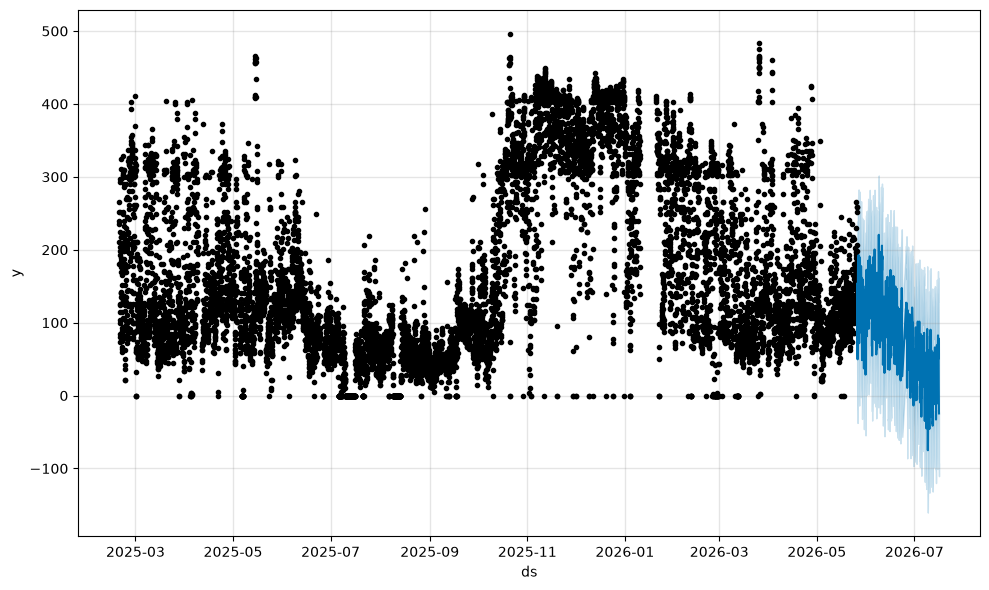

In [10]:
fig = model.plot(forecast)

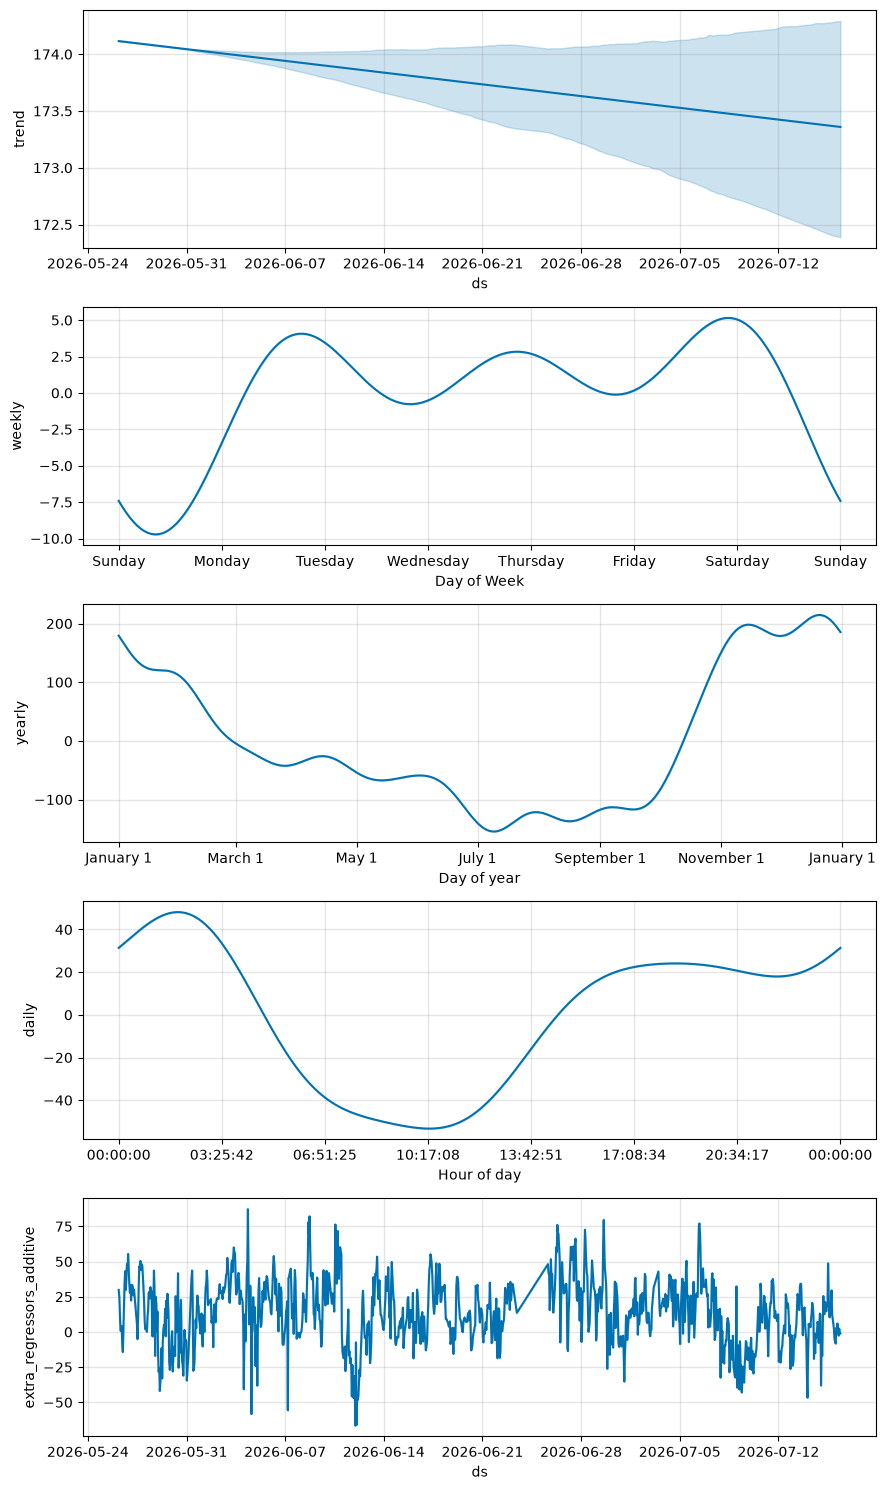

In [11]:
fig2 = model.plot_components(forecast)

In [12]:
import numpy as np
from sklearn.metrics import mean_squared_error

# ----------------------------
# Persistence Baseline
# ----------------------------

baseline_predictions = test["y"].shift(1)

baseline = pd.DataFrame({
    "actual": test["y"],
    "baseline": baseline_predictions
}).dropna()

baseline_rmse = np.sqrt(
    mean_squared_error(
        baseline["actual"],
        baseline["baseline"]
    )
)

print("=" * 60)
print("Persistence RMSE :", round(baseline_rmse, 2))
print("=" * 60)

Persistence RMSE : 29.32


In [13]:
forecast_eval = forecast.iloc[1:].copy()

prophet_rmse = np.sqrt(
    mean_squared_error(
        baseline["actual"],
        forecast_eval["yhat"]
    )
)

print("=" * 60)
print("Prophet RMSE :", round(prophet_rmse, 2))
print("=" * 60)

Prophet RMSE : 84.7


In [14]:
comparison = pd.DataFrame({

    "Model": [
        "Persistence",
        "Prophet"
    ],

    "RMSE": [
        baseline_rmse,
        prophet_rmse
    ]

})

comparison

,Model,RMSE
0,Persistence,29.322865
1,Prophet,84.699168


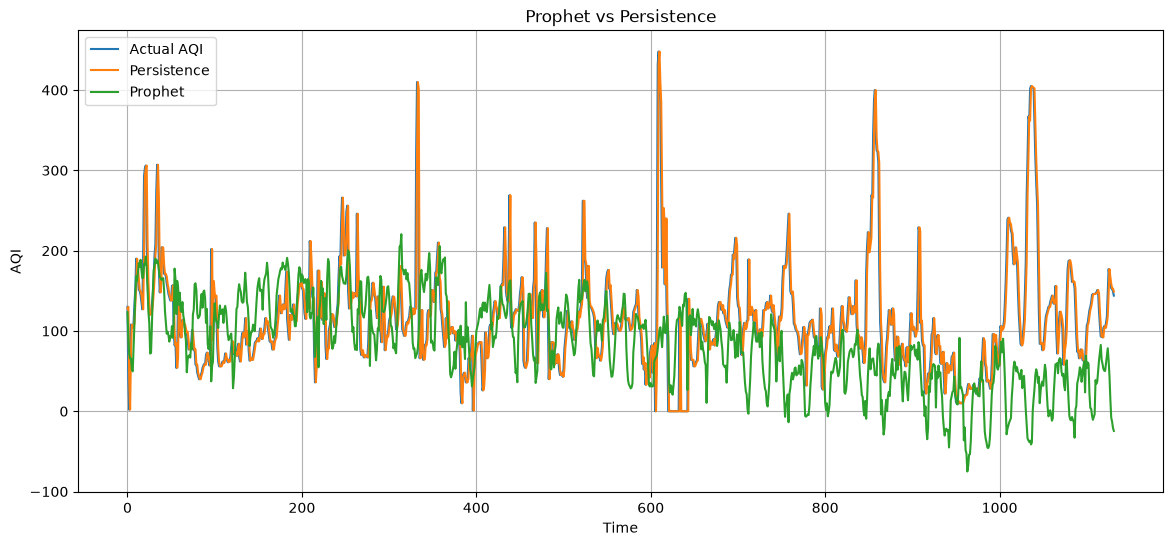

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(
    baseline["actual"].values,
    label="Actual AQI"
)

plt.plot(
    baseline["baseline"].values,
    label="Persistence"
)

plt.plot(
    forecast_eval["yhat"].values,
    label="Prophet"
)

plt.legend()

plt.title("Prophet vs Persistence")

plt.xlabel("Time")

plt.ylabel("AQI")

plt.grid(True)

plt.show()

In [16]:
forecast[
    [
        "ds",
        "yhat",
        "yhat_lower",
        "yhat_upper"
    ]
].head(20)

,ds,yhat,yhat_lower,yhat_upper
0,2026-05-26 04:30:00,153.269754,67.898031,238.537327
1,2026-05-26 05:30:00,123.272061,36.889240,209.748264
2,2026-05-26 06:30:00,92.966822,6.058890,176.350693
3,2026-05-26 07:30:00,70.851957,-15.743666,162.292722
4,2026-05-26 08:30:00,65.751422,-20.389834,150.733594
5,2026-05-26 09:30:00,65.582163,-19.192353,151.380476
6,2026-05-26 10:30:00,52.018650,-27.921710,138.612493
7,2026-05-26 11:30:00,49.704195,-37.545443,135.975384
8,2026-05-26 12:30:00,77.998738,-8.127951,161.679886
9,2026-05-26 13:30:00,109.861658,25.866789,193.740812


In [17]:
print(train["y"].describe())

count    10191.000000
mean       167.926798
std        121.122960
min          0.000000
25%         76.000000
50%        124.000000
75%        269.000000
max        496.000000
Name: y, dtype: float64


In [18]:
print(test["y"].describe())

count    1133.000000
mean      113.764342
std        63.401659
min         0.000000
25%        77.000000
50%       106.000000
75%       136.000000
max       448.000000
Name: y, dtype: float64


In [19]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=True,
    changepoint_prior_scale=0.1
)

In [20]:
print("Training Prophet...")

model.fit(train)

print("Training Complete!")

Training Prophet...


18:48:26 - cmdstanpy - INFO - Chain [1] start processing
18:48:27 - cmdstanpy - INFO - Chain [1] done processing


Training Complete!


In [21]:
future = test[["ds"]]

forecast = model.predict(future)

In [22]:
import numpy as np
from sklearn.metrics import mean_squared_error

prophet_rmse = np.sqrt(
    mean_squared_error(
        test["y"],
        forecast["yhat"]
    )
)

print("="*60)
print("Prophet (AQI Only) RMSE :", round(prophet_rmse,2))
print("="*60)

Prophet (AQI Only) RMSE : 87.65


,Model,RMSE
0,Persistence,29.322865
1,Prophet + Weather,84.700000
2,Prophet (AQI Only),87.649785


In [24]:
import pandas as pd
from pathlib import Path

# ----------------------------
# Load merged dataset
# ----------------------------

df = pd.read_csv("3715_merged.csv")

# ----------------------------
# Calculate AQI
# ----------------------------

from math import isnan

PM25_BREAKPOINTS = [
    (0,30,0,50),
    (31,60,51,100),
    (61,90,101,200),
    (91,120,201,300),
    (121,250,301,400),
    (251,1000,401,500)
]

PM10_BREAKPOINTS = [
    (0,50,0,50),
    (51,100,51,100),
    (101,250,101,200),
    (251,350,201,300),
    (351,430,301,400),
    (431,2000,401,500)
]

def subindex(c, bp):
    if pd.isna(c):
        return None

    for cl,ch,al,ah in bp:
        if cl <= c <= ch:
            return round(((ah-al)/(ch-cl))*(c-cl)+al)

    return None

def calculate_aqi(pm25, pm10):
    p25 = subindex(pm25, PM25_BREAKPOINTS)
    p10 = subindex(pm10, PM10_BREAKPOINTS)

    vals = [x for x in [p25,p10] if x is not None]

    if not vals:
        return None

    return max(vals)

df["y"] = df.apply(
    lambda r: calculate_aqi(r.pm25, r.pm10),
    axis=1
)

# ----------------------------
# Sort
# ----------------------------

df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

# ----------------------------
# Lag Features
# ----------------------------

df["lag1"] = df["y"].shift(1)
df["lag2"] = df["y"].shift(2)
df["lag3"] = df["y"].shift(3)

df["rolling3"] = (
    df["lag1"] +
    df["lag2"] +
    df["lag3"]
) / 3

# ----------------------------
# Keep features
# ----------------------------

training = df[
    [
        "datetime",
        "lag1",
        "lag2",
        "lag3",
        "rolling3",
        "temperature",
        "humidity",
        "precipitation",
        "wind_speed",
        "wind_direction",
        "y"
    ]
].copy()

training.dropna(inplace=True)

training.to_csv(
    "3715_training.csv",
    index=False
)

print("="*60)
print("Training dataset created")
print("="*60)
print(training.head())
print()
print(training.describe())
print()
print("Rows:", len(training))

Training dataset created
                   datetime   lag1   lag2   lag3    rolling3  temperature  \
3 2025-02-18 22:30:00+00:00  181.0  211.0  239.0  210.333333         16.4   
4 2025-02-18 23:30:00+00:00  252.0  181.0  211.0  214.666667         15.8   
5 2025-02-19 00:30:00+00:00  266.0  252.0  181.0  233.000000         15.3   
6 2025-02-19 01:30:00+00:00  235.0  266.0  252.0  251.000000         14.6   
7 2025-02-19 02:30:00+00:00  225.0  235.0  266.0  242.000000         14.9   

   humidity  precipitation  wind_speed  wind_direction      y  
3        61            0.0         5.2             282  252.0  
4        62            0.0         5.4             290  266.0  
5        64            0.0         5.4             285  235.0  
6        71            0.0         4.6             283  225.0  
7        70            0.0         5.6             276  252.0  

               lag1          lag2          lag3      rolling3   temperature  \
count  11291.000000  11291.000000  11291.000000 

In [25]:
import pickle
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

from xgboost import XGBRegressor

import numpy as np

In [26]:
df = pd.read_csv("3715_training.csv")

print(df.head())

print()

print(df.shape)

                    datetime   lag1   lag2   lag3    rolling3  temperature  \
0  2025-02-18 22:30:00+00:00  181.0  211.0  239.0  210.333333         16.4   
1  2025-02-18 23:30:00+00:00  252.0  181.0  211.0  214.666667         15.8   
2  2025-02-19 00:30:00+00:00  266.0  252.0  181.0  233.000000         15.3   
3  2025-02-19 01:30:00+00:00  235.0  266.0  252.0  251.000000         14.6   
4  2025-02-19 02:30:00+00:00  225.0  235.0  266.0  242.000000         14.9   

   humidity  precipitation  wind_speed  wind_direction      y  
0        61            0.0         5.2             282  252.0  
1        62            0.0         5.4             290  266.0  
2        64            0.0         5.4             285  235.0  
3        71            0.0         4.6             283  225.0  
4        70            0.0         5.6             276  252.0  

(11291, 11)


In [27]:
FEATURES = [

    "lag1",
    "lag2",
    "lag3",

    "rolling3",

    "temperature",
    "humidity",
    "precipitation",
    "wind_speed",
    "wind_direction"

]

TARGET = "y"

In [28]:
train_size = int(len(df) * 0.9)

train = df.iloc[:train_size]
test = df.iloc[train_size:]

X_train = train[FEATURES]
y_train = train[TARGET]

X_test = test[FEATURES]
y_test = test[TARGET]

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (10161, 9)
Testing : (1130, 9)


In [29]:
model = XGBRegressor(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    random_state=42

)

In [30]:
print("Training XGBoost...")

model.fit(
    X_train,
    y_train
)

print("Training Complete!")

Training XGBoost...
Training Complete!


In [31]:
predictions = model.predict(X_test)

In [32]:
rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

mae = mean_absolute_error(
    y_test,
    predictions
)

print("="*60)

print("RMSE :", round(rmse,2))

print("MAE  :", round(mae,2))

RMSE : 30.29
MAE  : 17.48


In [33]:
baseline = test["y"].shift(1)

baseline_df = pd.DataFrame({

    "actual": y_test,

    "baseline": baseline

}).dropna()

baseline_rmse = np.sqrt(

    mean_squared_error(

        baseline_df["actual"],

        baseline_df["baseline"]

    )

)

print()

print("Persistence RMSE :", round(baseline_rmse,2))


Persistence RMSE : 29.24


In [34]:
comparison = pd.DataFrame({

    "Model":[

        "Persistence",

        "XGBoost"

    ],

    "RMSE":[

        baseline_rmse,

        rmse

    ]

})

comparison

,Model,RMSE
0,Persistence,29.241580
1,XGBoost,30.294295


In [35]:
with open(
    "3715.pkl",
    "wb"
) as f:

    pickle.dump(
        model,
        f
    )

print("Model saved as 3715.pkl")

Model saved as 3715.pkl


In [36]:
importance = pd.DataFrame({

    "Feature": FEATURES,

    "Importance": model.feature_importances_

})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

          Feature  Importance
0            lag1    0.683340
3        rolling3    0.206539
1            lag2    0.027908
4     temperature    0.017881
2            lag3    0.016002
7      wind_speed    0.013851
5        humidity    0.012293
8  wind_direction    0.012156
6   precipitation    0.010031


Model V2 XGBoost

In [37]:
df = pd.read_csv("3715_training.csv")

In [38]:
merged = pd.read_csv("3715_merged.csv")

In [39]:
merged["y"] = merged.apply(
    lambda r: calculate_aqi(
        r.pm25,
        r.pm10
    ),
    axis=1
)

merged["datetime"] = pd.to_datetime(
    merged["datetime"]
)

merged = merged.sort_values(
    "datetime"
)

In [40]:
merged["lag1"] = merged["y"].shift(1)
merged["lag2"] = merged["y"].shift(2)
merged["lag3"] = merged["y"].shift(3)

merged["rolling3"] = (
    merged["lag1"] +
    merged["lag2"] +
    merged["lag3"]
) / 3

In [41]:
training = merged[
    [

        "lag1",
        "lag2",
        "lag3",
        "rolling3",

        "co",
        "no",
        "no2",
        "nox",
        "o3",
        "pm10",
        "pm25",
        "so2",

        "temperature",
        "humidity",
        "precipitation",
        "wind_speed",
        "wind_direction",

        "y"

    ]
].dropna()

In [42]:
FEATURES = [

    "lag1",
    "lag2",
    "lag3",
    "rolling3",

    "co",
    "no",
    "no2",
    "nox",
    "o3",
    "pm10",
    "pm25",
    "so2",

    "temperature",
    "humidity",
    "precipitation",
    "wind_speed",
    "wind_direction"

]

In [ ]:
import requests
import pandas as pd
from datetime import datetime, timedelta

# OpenAQ Location ID for Mandir Marg, Delhi
# If 2554 returns no data, grab the ID from the explore.openaq.org URL for this station
location_ids = [2554] 

headers = {"X-API-Key": "8b9ca36f6f781c95db339cb2cf5dfd03681e41e18a7a44d3a049e33687daa50c"}

# Define the 3-year historical window
end_date = datetime.utcnow()
start_date = end_date - timedelta(days=3*365)

# Format dates for the API
date_to = end_date.strftime('%Y-%m-%dT%H:%M:%SZ')
date_from = start_date.strftime('%Y-%m-%dT%H:%M:%SZ')

all_data = []

for loc_id in location_ids:
    print(f"Fetching sensors for Location {loc_id} (Mandir Marg)...")
    loc_response = requests.get(f"https://api.openaq.org/v3/locations/{loc_id}", headers=headers).json()
    
    # Safety check in case the API limits, returns an error, or the ID is wrong
    if 'results' not in loc_response or not loc_response['results']:
        print(f"Error or no data found for location {loc_id}. Double-check the internal location ID.")
        continue
        
    # Extract the array of sensors (PM2.5, PM10, etc.) for this location
    sensors = loc_response['results'][0]['sensors']
    
    for sensor in sensors:
        sensor_id = sensor['id']
        parameter = sensor['parameter']['name']
        print(f"  -> Pulling 3 years of {parameter} (Sensor ID: {sensor_id})")
        
        page = 1
        while True:
            # Hitting the precomputed hours endpoint for data efficiency
            url = f"https://api.openaq.org/v3/sensors/{sensor_id}/hours"
            params = {
                "date_from": date_from,
                "date_to": date_to,
                "limit": 1000, # Maximize the payload per request
                "page": page
            }
            
            res = requests.get(url, headers=headers, params=params).json()
            results = res.get('results', [])
            
            if not results:
                break
                
            for row in results:
                all_data.append({
                    "location_id": loc_id,
                    "parameter": parameter,
                    "datetime": row['period']['datetimeFrom']['utc'],
                    "value": row['value']
                })
            
            # If we hit a page with less than 1000 results, we reached the end
            if len(results) < 1000:
                break
                
            page += 1

# Ensure data was collected before attempting to format and save
if all_data:
    # Convert to a DataFrame and pivot into the "wide" format Prophet expects
    df = pd.DataFrame(all_data)
    df_wide = df.pivot_table(index=['location_id', 'datetime'], columns='parameter', values='value').reset_index()

    # Save it locally as requested
    df_wide.to_csv("2554.csv", index=False)
    print("Download complete and saved to 2554.csv!")
else:
    print("No data was retrieved. File was not saved.")

C:\Users\Sarosh\AppData\Local\Temp\ipykernel_3212\1057106130.py:12: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end_date = datetime.utcnow()


Fetching sensors for Location 2554 (Mandir Marg)...
  -> Pulling 3 years of co (Sensor ID: 5158)
  -> Pulling 3 years of no2 (Sensor ID: 28611)


In [ ]:
import requests
import pandas as pd
from datetime import datetime, timedelta

# Coordinates for Mandir Marg, Delhi
latitude = 28.6341
longitude = 77.2005

# Define the 3-year historical window
end_date = datetime.utcnow()
start_date = end_date - timedelta(days=3*365)

# Open-Meteo expects dates in YYYY-MM-DD format
start_date_str = start_date.strftime('%Y-%m-%d')
end_date_str = end_date.strftime('%Y-%m-%d')

print(f"Fetching 3 years of weather data for Mandir Marg (Station 2554)...")
print(f"Range: {start_date_str} to {end_date_str}")

# The Archive API endpoint for historical data
url = "https://archive-api.open-meteo.com/v1/archive"

# Parameters matching the requirements for your forecasting/attribution models
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date_str,
    "end_date": end_date_str,
    "hourly": ["temperature_2m", "relative_humidity_2m", "wind_speed_10m", "wind_direction_10m", "precipitation"],
    "timezone": "UTC" # Kept in UTC for clean merging with OpenAQ data
}

# Make the request
response = requests.get(url, params=params)

if response.status_code == 200:
    data = response.json()
    
    # Open-Meteo returns a dictionary of arrays. We load this directly into pandas.
    hourly_data = data['hourly']
    
    # Create the DataFrame
    weather_df = pd.DataFrame({
        "datetime": hourly_data['time'], # Merge key
        "temperature_c": hourly_data['temperature_2m'],
        "humidity_percent": hourly_data['relative_humidity_2m'],
        "wind_speed_kmh": hourly_data['wind_speed_10m'],
        "wind_dir_deg": hourly_data['wind_direction_10m'],
        "precip_mm": hourly_data['precipitation']
    })
    
    # Save to CSV
    filename = "weather_history_2554.csv"
    weather_df.to_csv(filename, index=False)
    print(f"Success! {len(weather_df)} hourly records saved to {filename}")
    
else:
    print(f"Error fetching data: HTTP {response.status_code}")
    print(response.text)